In [43]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import numpy as np

In [ ]:
def plot_clusters(data, labels, title, centers=None):
    """Точки, раскрашенные по номеру кластера; при наличии - центры."""
    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)

    for cluster in range(N_CLUSTERS):
        cluster_points = data[labels == cluster]
        ax.scatter(
            cluster_points["x"],
            cluster_points["y"],
            s=POINT_SIZE,
            color=plt.cm.tab20(cluster % 20),
            label=f"Cluster {cluster}",
        )

    if centers is not None:
        ax.scatter(
            centers[:, 0],
            centers[:, 1],
            s=CENTER_SIZE,
            c="black",
            marker="X",
            label="Centroids",
        )

    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), markerscale=3)
    plt.show()

In [45]:
data = pd.read_csv("s1.txt", sep=r"\s+", header=None, names=["x", "y"]) # резать по пробелам потому что тэикстэ

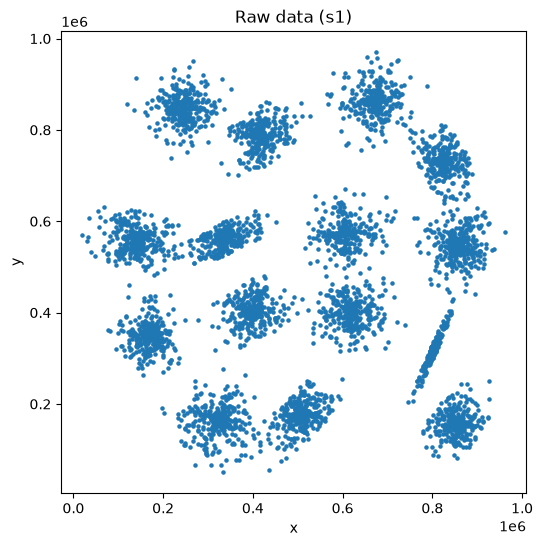

In [46]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(data["x"], data["y"], s=5)
ax.set_title("Raw data (s1)")
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.show()

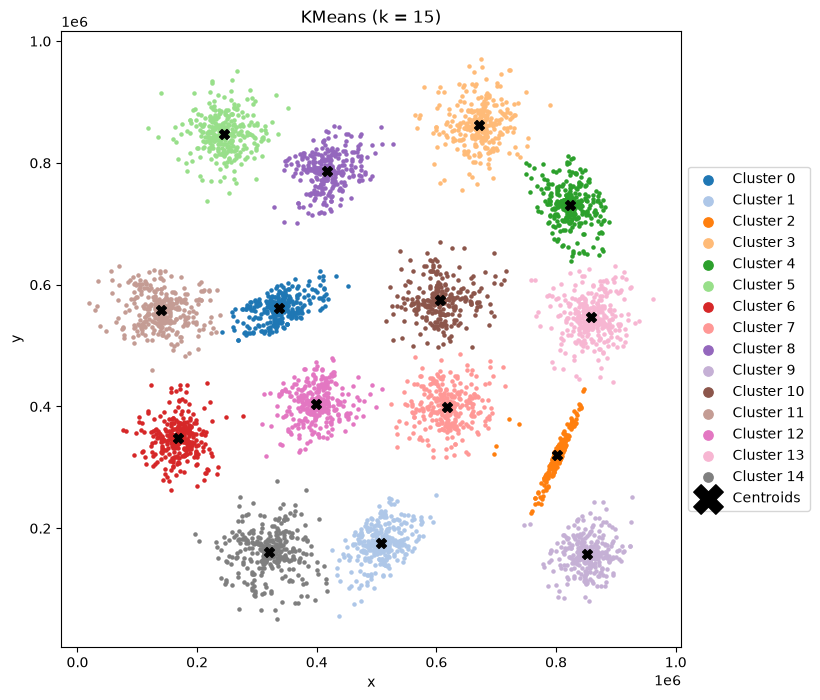

In [47]:
PLOT_FIGSIZE = (8, 8)
POINT_SIZE = 5
CENTER_SIZE = 50
N_CLUSTERS = 15

kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42)
kmeans_labels = kmeans.fit_predict(data)

plot_clusters(data, kmeans_labels, "KMeans (k = 15)", kmeans.cluster_centers_)

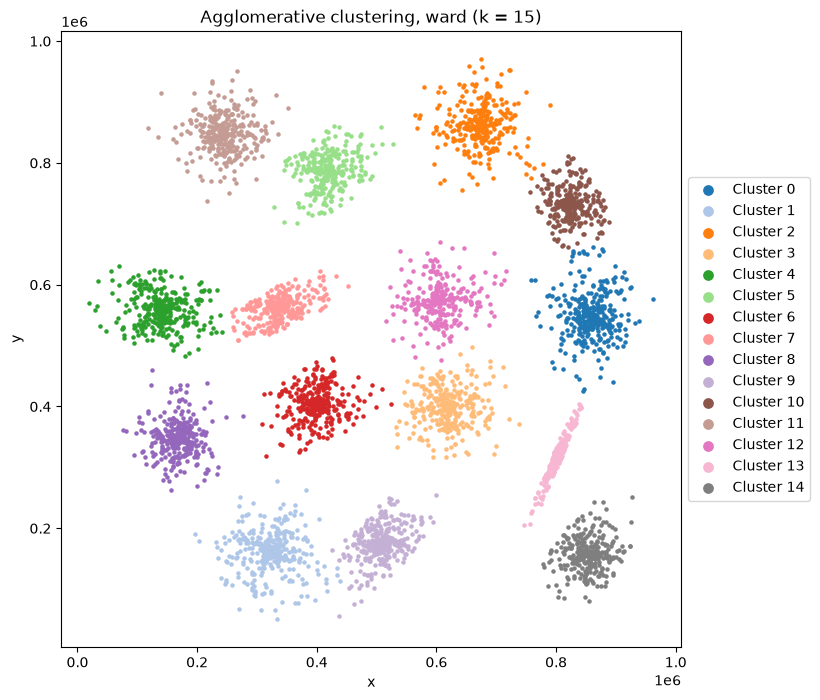

In [48]:
from sklearn.cluster import AgglomerativeClustering

agglomerative = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage="ward") # самые ближние точки 
agglomerative_labels = agglomerative.fit_predict(data)

plot_clusters(data, agglomerative_labels, "Agglomerative clustering, ward (k = 15)")

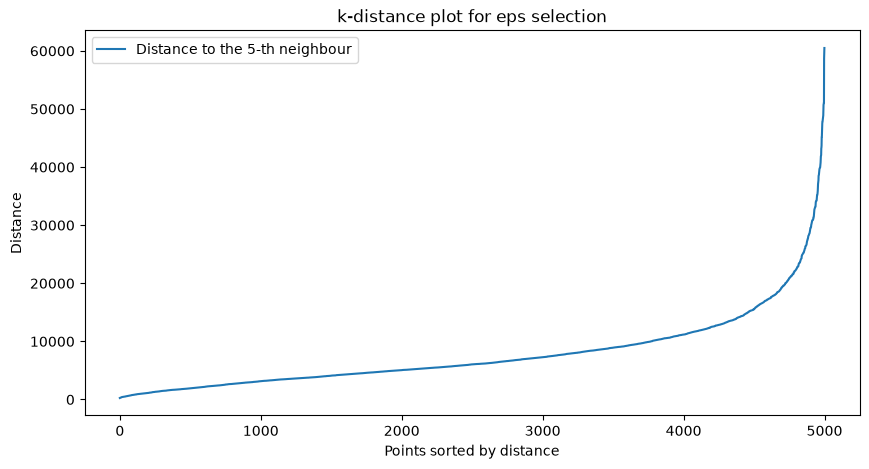

In [49]:
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 5

neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES)
neighbors.fit(data)
distances, indices = neighbors.kneighbors(data)

k_distances = np.sort(distances[:, -1])

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_distances, label=f"Distance to the {MIN_SAMPLES}-th neighbour")
ax.set_xlabel("Points sorted by distance")
ax.set_ylabel("Distance")
ax.set_title("k-distance plot for eps selection")
ax.legend()
plt.show()